# 7 · Where the search's error comes from

Before a network is put on top of the tile search, this asks what it would have to learn.
The search assumes three things - one rigid motion per tile, going on at the same speed, and
that every change is a motion - and every scene records what really happened on each frame:
the background's scroll, a region scrolling inside the window, a window dragged, a menu
opening. So every client tile at a generated frame N+1 is labelled by what touched it
between the received frame N-2 and N+1, and the search's error there is set beside three
oracles, each of which sees N+1:

| oracle | what it may choose | what it shows the room for |
| --- | --- | --- |
| **share** | per tile, the best of 17 shares of the search's motion, 0 to all of it | whether the motion goes on, stops or changes speed - notebook 6 |
| **cell** | per 16x16 cell, the best of repeat, the tile's motion, the 64 and 32 px blocks' motions and two more minima of the tile's cost | that, and *where* each motion is - notebook 4's candidates |
| **motion** | per 16 px block, the motion from N to N+1 itself, found by searching between them | any motion at all, known exactly; what it leaves is not motion - new content, codec noise |

The error is the weighted Y'CbCr squared error the score uses, summed over the region the
client keeps from each tile: it adds up across tiles, so the search's error can be split by
label and each oracle's share of it read off - a budget, which averages of dB cannot give.

Steps:

1. **Data** - every validation tile, labelled, with the five errors.
2. **The budget** - the search's error by label, and what each oracle takes back.
3. **By family** - the labels grouped by what a network could know about them.
4. **What it looks like** - a tile of each of the largest labels.

Nothing is trained or exported. Needs: `00_data_preprocess.ipynb` and the sources it read.

A tile's label is the first of these that touched it, in order of how little the frames
before say about it: a menu opening or closing at N+1; one that did between N-2 and N; a
window dragged; a region scrolling; the background scrolling - each motion *starting*
(still from N-2 to N, moving after), *stopping*, *changing speed* (by more than one stream
pixel from half its last motion) or *going on*; video; nothing recorded.

In [1]:
"""Settings."""

import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import budget, clips, metrics, models, runs, show, training
from helpers.training import DEVICE

RADIUS, SCALE, SHARPNESS, STRIDE, STILL = 4, 2, 10.0, 2, 0.1   # notebook 3's published search
EVERY = 1        # a sample at every received frame N from N = 2
CACHE = training.CHECKPOINT_DIR / "budget"
ORACLES = ("share", "cell", "motion")
SERIES = {"share": "#2a78d6", "cell": "#eb6834", "motion": "#1baf7a"}   # the reference palette's slots 1-3
INK, MUTED = "#3d3d3a", "#8a8a85"
SEED = 0
training.seed_everything(SEED)

## 1. Data

Every validation source rebuilt from the manifest and cut into the client's tiles, at every
received frame N: the tile's labels (`budget.events`), and the summed error of repeat, the
published search and the three oracles (`budget.oracles`). The tiles counted are the
**active** ones - the search's gate is open (something moved from N-2 to N) or N+1 differs
from N - since on the others every method returns N and N is right.

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
search = models.TileSearch(RADIUS, SCALE, SHARPNESS, STRIDE, 1 / runs.received_every(manifest), still=STILL).to(DEVICE).eval()

CACHE.mkdir(parents=True, exist_ok=True)
path = CACHE / f"val_r{RADIUS}_s{STRIDE}_e{EVERY}.pkl"
started = time.time()
if path.exists() and path.stat().st_mtime > (training.DATA_DIR / "manifest.json").stat().st_mtime:
    table = pickle.loads(path.read_bytes())
else:
    table = budget.load(manifest, "val", search, EVERY)
    path.write_bytes(pickle.dumps(table))
error, pixels = table["error"], table["pixels"]
active = table["changed"] | table["moving"]
print(f"{len(active)} tiles from {len(set(table['source']))} clips in {time.time() - started:.0f}s: "
      f"{active.sum()} active ({table['moving'].sum()} moving from N-2 to N, {table['changed'].sum()} changed to N+1)")
print(f"the search's error outside the active tiles: {error['search'][~active].sum() / error['search'].sum():.2%} of all of it")

for name in ("share", "cell"):     # both may choose repeat; the motion oracle may not
    assert (error[name] <= error["repeat"] + 1e-3).all()
assert (error["share"] <= error["search"] + 1e-3).all() and (error["cell"] <= error["search"] + 1e-3).all()

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)
13155 tiles from 115 clips in 0s: 7728 active (7417 moving from N-2 to N, 5319 changed to N+1)
the search's error outside the active tiles: 0.04% of all of it


## 2. The budget

Per label, over the active tiles: how many, their share of the search's whole error, the
mean wPSNR of repeat and the search, and the share of the search's error there that each
oracle takes back. The motion oracle is not a bound on the others - it picks a motion per
block by luma alone, so on a tile holding a cut it can do worse than a choice among fewer.

In [3]:
labels = np.array(table["label"])
order = [label for label in budget.LABELS if (labels[active] == label).any()]
total = error["search"][active].sum()
rows = []
for label in order + ["all active"]:
    chosen = active & ((labels == label) if label != "all active" else True)
    found = {name: error[name][chosen].sum() for name in error}
    rows.append({"label": label, "tiles": int(chosen.sum()), "of the error": found["search"] / total,
                 "repeat dB": budget.wpsnr(error["repeat"][chosen], pixels[chosen]).mean(),
                 "search dB": budget.wpsnr(error["search"][chosen], pixels[chosen]).mean(),
                 **{name: 1 - found[name] / found["search"] for name in ORACLES}})

print(f"{'active tiles, by label':<34}{'tiles':>7}{'of the error':>14}{'repeat dB':>11}{'search dB':>11}"
      + "".join(f"{f'{name} takes':>13}" for name in ORACLES))
for row in rows:
    if row["label"] == "all active":
        print("-" * 115)
    print(f"{row['label']:<34}{row['tiles']:7}{row['of the error']:14.1%}{row['repeat dB']:11.2f}{row['search dB']:11.2f}"
          + "".join(f"{row[name]:13.0%}" for name in ORACLES))

active tiles, by label              tiles  of the error  repeat dB  search dB  share takes   cell takes motion takes
menu opened or closed before N         45          0.5%      51.01      52.48          31%          37%          86%
drag: starts                           74          1.2%      29.27      30.57           8%          20%          73%
drag: stops                            56          0.4%      56.24      46.64          59%          73%          87%
drag: changes speed                   545         13.7%      27.82      28.80          10%          22%          70%
drag: goes on                          72          2.2%      24.24      25.52          23%          28%          68%
region: starts                        104          1.5%      29.54      29.54           0%           1%          82%
region: stops                          90          0.2%      79.36      71.94          99%          99%          99%
region: changes speed                 285          5.9%      29.

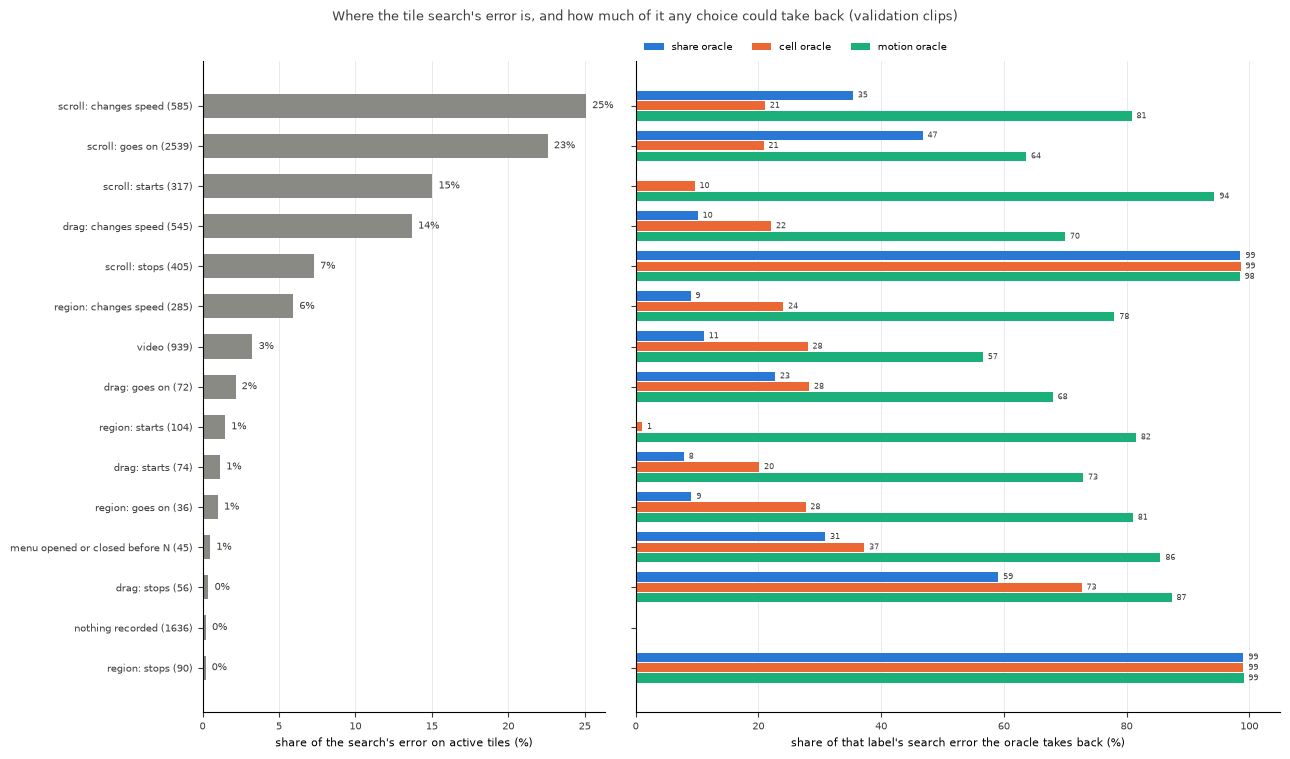

In [4]:
"""The budget drawn: left, each label's share of the search's error; right, the share of it
each oracle takes back. Labels in order of their share."""

shown = sorted([row for row in rows if row["label"] != "all active"], key=lambda row: row["of the error"])
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 0.42 * len(shown) + 1.4), sharey=True,
                                  gridspec_kw={"width_ratios": (1, 1.6)})
positions = np.arange(len(shown))
left.barh(positions, [row["of the error"] * 100 for row in shown], height=0.6, color=MUTED)
for y, row in zip(positions, shown):
    left.text(row["of the error"] * 100 + 0.4, y, f"{row['of the error']:.0%}", va="center", fontsize=7, color=INK)
left.set_yticks(positions, [f"{row['label']} ({row['tiles']})" for row in shown], fontsize=8)
left.set_xlabel("share of the search's error on active tiles (%)", fontsize=8)
height = 0.26
for k, name in enumerate(ORACLES):
    values = [max(0.0, row[name]) * 100 for row in shown]
    right.barh(positions + (1 - k) * height, values, height=height - 0.03, color=SERIES[name], label=f"{name} oracle")
    for y, value in zip(positions + (1 - k) * height, values):
        if value >= 1:
            right.text(value + 0.8, y, f"{value:.0f}", va="center", fontsize=6, color=INK)
right.set_xlim(0, 105)
right.set_xlabel("share of that label's search error the oracle takes back (%)", fontsize=8)
right.legend(fontsize=7, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False)
for ax in (left, right):
    ax.tick_params(labelsize=7, colors=INK)
    ax.grid(axis="x", color="#e6e6e3", lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.suptitle("Where the tile search's error is, and how much of it any choice could take back (validation clips)",
             fontsize=9, color=INK)
fig.tight_layout()
plt.show()

## 3. By family

The labels grouped by what the client could know about them before N+1 arrives:

- **unannounced** - a menu opening or closing at N+1, a motion starting: nothing before N+1
  shows it. No model can learn it from the frames; the client's own input could;
- **announced change** - a menu that opened or closed between N-2 and N: the search reads a
  change as a motion. The frames show it is not one;
- **part of the tile moves** - a dragged window, a scrolled region: the motion is in the
  frames, for part of the tile only;
- **the whole tile moves** - the background scroll: one motion is right; what it misses is
  when it stops or changes speed;
- **video**, and **nothing recorded** - codec noise, and what the scene does not label.

In [5]:
FAMILIES = {
    "unannounced": lambda label: label in ("menu opens or closes at N+1",) or label.endswith(": starts"),
    "announced change": lambda label: label == "menu opened or closed before N",
    "part of the tile moves": lambda label: label.startswith(("drag", "region")) and not label.endswith(": starts"),
    "whole tile moves": lambda label: label.startswith("scroll") and not label.endswith(": starts"),
    "video": lambda label: label == "video",
    "nothing recorded": lambda label: label == "nothing recorded",
}
family = np.array([next(name for name, test in FAMILIES.items() if test(label)) for label in labels])
print(f"{'active tiles, by family':<28}{'tiles':>7}{'of the error':>14}{'search dB':>11}"
      + "".join(f"{f'{name} takes':>13}" for name in ORACLES) + f"{'left to cell':>14}")
for name in FAMILIES:
    chosen = active & (family == name)
    if not chosen.any():
        continue
    searched = error["search"][chosen].sum()
    print(f"{name:<28}{chosen.sum():7}{searched / total:14.1%}{budget.wpsnr(error['search'][chosen], pixels[chosen]).mean():11.2f}"
          + "".join(f"{1 - error[o][chosen].sum() / searched:13.0%}" for o in ORACLES)
          + f"{error['cell'][chosen].sum() / total:14.1%}")
print("\n'left to cell': the share of the whole search error the cell oracle does not take back there")

active tiles, by family       tiles  of the error  search dB  share takes   cell takes motion takes  left to cell
unannounced                     495         17.7%      25.69           1%          10%          92%         16.0%
announced change                 45          0.5%      52.48          31%          37%          86%          0.3%
part of the tile moves         1084         23.4%      33.14          13%          25%          73%         17.6%
whole tile moves               3529         55.0%      33.95          48%          31%          76%         37.8%
video                           939          3.3%      45.49          11%          28%          57%          2.4%
nothing recorded               1636          0.2%      51.98           0%           0%         -27%          0.2%

'left to cell': the share of the whole search error the cell oracle does not take back there


## 4. What it looks like

For the four labels with the most error, the tile where the search does worst: the change
from N to N+1, and the error of the search, the cell oracle and the motion oracle.

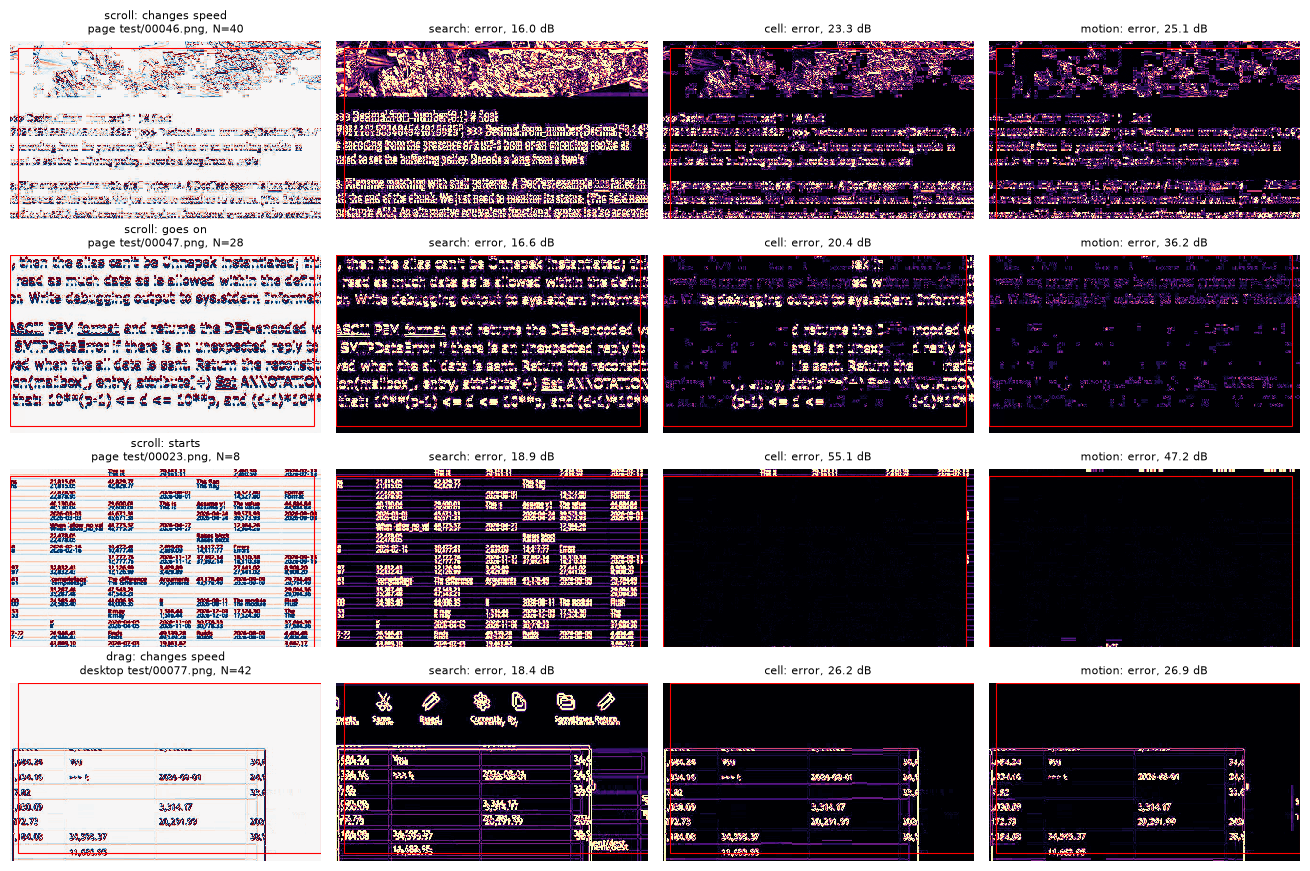

changes and errors full colour at 48 luma levels


In [6]:
largest = [row["label"] for row in sorted(rows[:-1], key=lambda row: -row["of the error"])[:4]]
columns = ["change N -> N+1", "search: error", "cell oracle: error", "motion oracle: error"]
fig, axes = plt.subplots(len(largest), len(columns), figsize=(3.3 * len(columns), 2.2 * len(largest)), squeeze=False)
sources = manifest["splits"]["val"]["sources"]
step = runs.received_every(manifest)
for row, label in enumerate(largest):
    chosen = np.flatnonzero(active & (labels == label))
    index = chosen[np.argmax(error["search"][chosen] - error["cell"][chosen])]
    source = sources[table["source"][index]]
    stream = clips.rebuild(source, manifest)
    layout, size = clips.plan(stream.shape[2], stream.shape[1])
    ix, iy = layout[table["tile"][index]][:2]
    n = table["frame"][index]
    window = stream[[n - step, n, n + 1], iy:iy + size[0], ix:ix + size[1]]
    previous, current, target = training.to_tensor(window[None]).unbind(1)
    box = tuple(table["box"][index])
    found, made = budget.oracles(search, previous, current, target, box, keep=True)
    ax = axes[row]
    show.change(ax[0], current, target, f"{label}\n{source['kind']} {source['file'][-14:]}, N={n}", box)
    for column, name in enumerate(("search", "cell", "motion"), start=1):
        score = metrics.wpsnr(clips.kept(made[name], box), clips.kept(target, box))
        show.error(ax[column], made[name], target, f"{name}: error, {score:.1f} dB", box)
fig.tight_layout()
plt.show()
print(f"changes and errors full colour at {show.LEVELS} luma levels")

## The search's measurement, against the scenes'

For the scrolls the share oracle takes most from - even steady ones, where nothing stops or
changes speed - the search's motion from N-2 to N set beside the scroll the scene recorded,
by how far the content really moved. The motions are notebook 6's, kept per tile.

In [7]:
from helpers import history

kept = history.restore(training.CHECKPOINT_DIR / "history" / "val_r4_s2_w8_d3_e1.npz")
where = {key: i for i, key in enumerate(zip(kept["source"], kept["frame"], kept["tile"]))}
scale = manifest["scale"]
for label in ("scroll: goes on", "scroll: changes speed"):
    chosen = [i for i in np.flatnonzero(active & (labels == label))
              if (table["source"][i], table["frame"][i], table["tile"][i]) in where]
    true, found, wide = [], [], []
    for i in chosen:
        scroll = np.array(sources[table["source"][i]]["scene"]["scroll"], float)
        n = table["frame"][i]
        true.append(-(scroll[n] - scroll[n - step]) / scale)          # content moves against the scroll
        j = where[(table["source"][i], n, table["tile"][i])]
        found.append(kept["motion"][j, 0])
        wide.append(kept["wide"][j, 0])
    true, found, wide = map(np.array, (true, found, wide))
    searched = error["search"][chosen]
    gained = searched - error["share"][chosen]
    speed = np.abs(true).max(1)
    print(f"\n{label}: {len(chosen)} tiles with history")
    for low, high in ((0, 2), (2, 4), (4, 8), (8, 12), (12, 99)):
        k = (speed >= low) & (speed < high)
        print(f"  moved {low:>2}-{high:<2} px from N-2 to N: {k.sum():4} tiles, {searched[k].sum() / searched.sum():5.1%} of the "
              f"label's error; search off by {np.median(np.linalg.norm(found[k] - true[k], axis=1)):5.2f} px (median), "
              f"±16 px search by {np.median(np.linalg.norm(wide[k] - true[k], axis=1)):5.2f}; share oracle takes {gained[k].sum() / searched[k].sum():4.0%}")


scroll: goes on: 2499 tiles with history
  moved  0-2  px from N-2 to N:  586 tiles, 15.9% of the label's error; search off by  0.50 px (median), ±16 px search by  0.50; share oracle takes  35%
  moved  2-4  px from N-2 to N:  732 tiles, 15.2% of the label's error; search off by  0.50 px (median), ±16 px search by  0.50; share oracle takes  60%
  moved  4-8  px from N-2 to N:  772 tiles, 23.2% of the label's error; search off by  0.50 px (median), ±16 px search by  0.50; share oracle takes  56%
  moved  8-12 px from N-2 to N:  214 tiles,  9.1% of the label's error; search off by  1.50 px (median), ±16 px search by  0.50; share oracle takes  69%
  moved 12-99 px from N-2 to N:  195 tiles, 36.7% of the label's error; search off by 12.84 px (median), ±16 px search by  0.52; share oracle takes  38%

scroll: changes speed: 546 tiles with history
  moved  0-2  px from N-2 to N:   24 tiles,  5.6% of the label's error; search off by  0.50 px (median), ±16 px search by  0.50; share oracle take

## What it says

- **More than half the search's error is on tiles that move whole** (55%: the background
  scrolling), a quarter on tiles that move in part (23%: a dragged window, a scrolled
  region), a sixth on what starts or opens without warning (18%), and little on video (3%),
  on menus that opened before N (0.5%) or on nothing at all (0.2%).
- **A large part of the whole-tile error is measurement, not prediction.** On steady scrolls
  (23% of the error), where the motion neither stops nor changes speed, the best share takes
  back 47% - because the search's motion is wrong: about half a stream pixel off below 8 px,
  and, for the fastest (over 12 px between received frames: 37% of the steady scrolls' error),
  past its ±8 px reach and off by ~13 px. A ±16 px search measures those to half a pixel. No
  network is needed for this: a search that reaches further and refines below a pixel is
  notebook 5's host measurement run on the client's two frames. Notebook 4 found ±16 px alone
  no better on whole tiles - the fast scrolls are also the ones easing in and out - so a wider
  reach needs the stop and speed decision beside it.
- **Speed changes are the largest label** (25%: wheel notches easing): the best share takes a
  third of it, and history (notebook 6) the part a slowdown announces.
- **Tiles that move in part are where a network belongs.** Notebook 4's candidates take only
  a quarter of their error (cell oracle 25%), but the true motion per 16 px block takes 73%:
  the right motion is not among the candidates, and finding it - which part of the tile moves,
  and how - is a segmentation with context, which a fixed search per block gets wrong. A
  dragged window follows the pointer exactly, and the client has the pointer's position.
- **What starts without warning is out of reach of any model** (18%: a scroll, a drag or a
  region starting, a menu at N+1): the search returns N there, and only the motion itself
  takes it back (92%) - which the client's own input would know, and its frames never do.

So the order is: measure the motion better first - a wider, sub-pixel search with the
history's stop decision, no training - then a network for the part of a tile that moves, with
the pointer as an input; the unannounced sixth is left to the client's input.